# ĐỀ 4: PHÂN TÍCH BỘ DỮ LIỆU HEART DISEASE (CLEVELAND) THEO NGUYÊN TẮC FAIR
- **Sinh viên:** Phan Trần Mai Uyên (MSSV: 3120225174)
- **Mục tiêu:** Phân tích sự khác biệt về lượng cholesterol giữa nhóm mắc bệnh và không mắc bệnh tim.

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

column_names = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
                'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
df = pd.read_csv(url, names=column_names)

print(f"Kích thước bộ dữ liệu ban đầu: {df.shape}")
df.head()

Kích thước bộ dữ liệu ban đầu: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


### Tiền xử lý dữ liệu
1. **Xử lý giá trị khuyết thiếu:** Trong dữ liệu Cleveland, giá trị thiếu được ký hiệu là `?` (nằm ở cột `ca` và `thal`). Ta sẽ chuyển `?` thành `NaN` và loại bỏ các hàng này vì tỷ lệ khuyết thiếu rất nhỏ (chỉ 6/303 dòng), không làm ảnh hưởng đến tính đại diện của mẫu.
2. **Chuẩn hóa biến mục tiêu:** Biến `target` gốc có giá trị từ 0 (không bệnh) đến 4. Ta sẽ đưa về dạng nhị phân: 0 (Không mắc bệnh) và 1 (Mắc bệnh).

In [8]:
df = df.replace('?', np.nan)
df = df.dropna()
print(f"Kích thước sau khi xóa dòng trống: {df.shape}")

df['target_binary'] = df['target'].apply(lambda x: 1 if x > 0 else 0)

df['chol'] = pd.to_numeric(df['chol'])
df['target_binary'] = pd.to_numeric(df['target_binary'])

Kích thước sau khi xóa dòng trống: (297, 14)


### Kiểm tra giả định phân phối
Để so sánh trung bình lượng Cholesterol giữa hai nhóm (Bệnh và Không Bệnh), ta cần kiểm tra xem phân phối của Cholesterol có chuẩn hay không để quyết định dùng T-test (tham số) hay Mann-Whitney (phi tham số).
H0: Dữ liệu phân phối chuẩn.

In [9]:
chol_no_disease = df[df['target_binary'] == 0]['chol']
chol_disease = df[df['target_binary'] == 1]['chol']

stat_no, p_no = stats.shapiro(chol_no_disease)
stat_yes, p_yes = stats.shapiro(chol_disease)

print(f"P-value nhóm không bệnh: {p_no:.4f}")
print(f"P-value nhóm có bệnh: {p_yes:.4f}")

P-value nhóm không bệnh: 0.0000
P-value nhóm có bệnh: 0.4319


In [10]:
t_stat, p_val = stats.ttest_ind(chol_disease, chol_no_disease, equal_var=False)

mean_diff = chol_disease.mean() - chol_no_disease.mean()
se_diff = np.sqrt(chol_disease.var(ddof=1)/len(chol_disease) + chol_no_disease.var(ddof=1)/len(chol_no_disease))
ci_lower = mean_diff - 1.96 * se_diff
ci_upper = mean_diff + 1.96 * se_diff

pooled_sd = np.sqrt(((len(chol_disease)-1)*chol_disease.var() + (len(chol_no_disease)-1)*chol_no_disease.var()) / (len(chol_disease) + len(chol_no_disease) - 2))
cohens_d = mean_diff / pooled_sd

print(f"--- KẾT QUẢ KIỂM ĐỊNH THỐNG KÊ ---")
print(f"Trung bình Cholesterol nhóm Bệnh: {chol_disease.mean():.2f}")
print(f"Trung bình Cholesterol nhóm Không Bệnh: {chol_no_disease.mean():.2f}")
print(f"Chênh lệch trung bình: {mean_diff:.2f}")
print(f"Khoảng tin cậy 95% (CI): [{ci_lower:.2f}, {ci_upper:.2f}]")
print(f"T-statistic: {t_stat:.4f}, P-value: {p_val:.4f}")
print(f"Độ lớn hiệu ứng (Cohen's d): {cohens_d:.4f}")

--- KẾT QUẢ KIỂM ĐỊNH THỐNG KÊ ---
Trung bình Cholesterol nhóm Bệnh: 251.85
Trung bình Cholesterol nhóm Không Bệnh: 243.49
Chênh lệch trung bình: 8.36
Khoảng tin cậy 95% (CI): [-3.41, 20.13]
T-statistic: 1.3919, P-value: 0.1650
Độ lớn hiệu ứng (Cohen's d): 0.1610


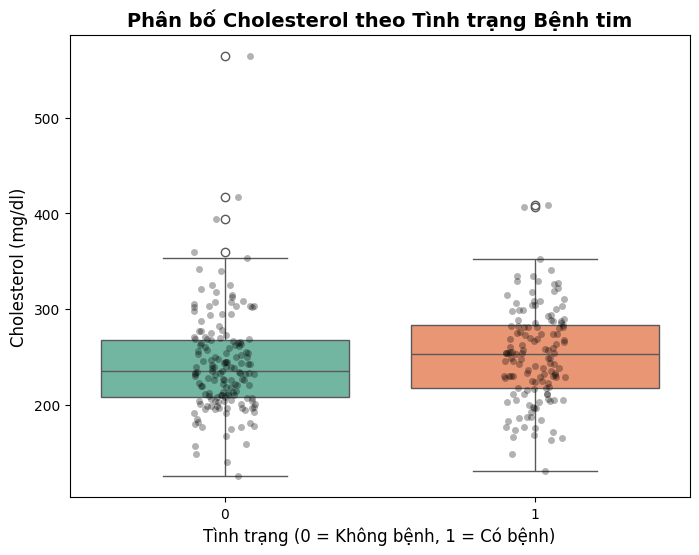

In [11]:
plt.figure(figsize=(8, 6))

sns.boxplot(x='target_binary', y='chol', data=df, hue='target_binary', palette='Set2', legend=False)
sns.stripplot(x='target_binary', y='chol', data=df, color='black', alpha=0.3)

plt.title('Phân bố Cholesterol theo Tình trạng Bệnh tim', fontsize=14, fontweight='bold')
plt.xlabel('Tình trạng (0 = Không bệnh, 1 = Có bệnh)', fontsize=12)
plt.ylabel('Cholesterol (mg/dl)', fontsize=12)

plt.savefig('cholesterol_comparison.png', dpi=300, bbox_inches='tight')
plt.show()